# Behavioural Prototype Graph Clustering (BPGC) — revised
### Dubai Metro Station Profiling — experimental notebook

**Input:** standardized 244 × 17 station-window features and *spatial* edges from `reference/edges.csv`. **No temporal edges are used anywhere** (fitting or evaluation).

BPGC alternates between prototype-centred assignments and spatial agreement updates:
\[
J(z,\mu)=\sum_i \|x_i-\mu_{z_i}\|^2+\lambda\,s\sum_{(i,j)\in E_s} w_{ij}\,\mathbf 1[z_i\ne z_j],
\]
where `s` is a single fixed scale (mean squared distance of a reference K-Means fit) so that λ is interpretable and objectives are comparable across restarts.
This is an **experimental combination** (closely related to HMRF-K-Means / Potts-prior ICM), not a claim of novelty.

**Changes vs. the previous version**
1. One shared penalty scale for all restarts (objectives now comparable).
2. Vectorised neighbour-mismatch update (no per-node `cdist`, no Python inner loop over neighbours).
3. Equal search budget: BPGC restarts = K-Means `n_init` (full data and stability runs).
4. Chance-corrected spatial consistency (kappa-style) alongside the raw value.
5. λ chosen by a stated rule (max chance-adjusted spatial consistency subject to a silhouette tolerance), not by max silhouette.
6. New baseline: **spatially constrained Ward** (connectivity = the same spatial graph).
7. Ncut also reported relative to its no-structure reference (`P-1`); DBSCAN degeneracy flagged via largest-cluster share.
8. Stability: shared helper for all methods, paired differences vs K-Means, stray `index` column removed.
9. K sweep added; optional removal of the redundant share bins.

## 1. Configuration

In [29]:
from pathlib import Path
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.spatial.distance import cdist, pdist, squareform
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors

SEED = 42
K = 6
DBSCAN_MIN_SAMPLES = 5
DBSCAN_EPS_PERCENTILE = 90
RESTARTS = 20                 # BPGC restarts == K-Means n_init (equal search effort)
KMEANS_INIT = RESTARTS
STAB_INIT = 10                # same budget for BPGC and K-Means inside stability runs
MAX_ITER = 60
INNER_SWEEPS = 12
LAMBDA_GRID = [0.0, 0.05, 0.1, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 4.0]
SIL_TOL = 0.04                # lambda rule: allow silhouette to drop at most this far below its best value
STABILITY_REPEATS = 20
K_RANGE = range(2, 11)
REDUCE_COLLINEAR = False      # True drops check_in/out_share_20_24 (each share group sums to 1)
USE_S3 = False
ROOT = Path.cwd().resolve()
if not (ROOT / "reference").exists() and (ROOT.parent / "reference").exists():
    ROOT = ROOT.parent
FEATURES_FILE = ROOT / "results/features/features.parquet"
EDGES_FILE = ROOT / "reference/edges.csv"
OUTPUT_DIR = ROOT / "results/bpgc"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)
print("Local features:", FEATURES_FILE.exists(), "| Spatial graph:", EDGES_FILE.exists())

Project root: /Users/aryanchandra/Downloads/Metro-Spectral-STGRSC
Local features: True | Spatial graph: True


## 2. Load and validate the feature table

In [30]:
def canonical_id(v):
    num = pd.to_numeric(pd.Series([v]), errors="coerce").iloc[0]
    return str(int(num)) if pd.notna(num) and float(num).is_integer() else str(v).strip()

if USE_S3:
    import boto3
    import awswrangler as wr
    session = boto3.Session(
        profile_name=os.environ.get("AWS_PROFILE") or None,
        region_name=os.environ.get("AWS_DEFAULT_REGION", "ap-south-1")
    )
    bucket = os.environ.get("METRO_S3_BUCKET")
    if not bucket:
        account = session.client("sts").get_caller_identity()["Account"]
        bucket = f"dubai-metro-profiling-{account}"
    df = wr.s3.read_parquet(f"s3://{bucket}/curated/features/", boto3_session=session)
else:
    if not FEATURES_FILE.exists():
        raise FileNotFoundError(f"Missing {FEATURES_FILE}. Set USE_S3=True for your existing AWS source.")
    df = pd.read_parquet(FEATURES_FILE)

KEY_COLUMNS = ["win", "location_id", "station"]
AUX_COLUMNS = ["timed_taps", "check_ins", "check_outs"]
required = KEY_COLUMNS + AUX_COLUMNS
if not set(required).issubset(df.columns):
    raise ValueError(f"Missing columns: {sorted(set(required)-set(df.columns))}")
if df.duplicated(["win", "location_id"]).any():
    raise ValueError("Duplicate station-window keys")
df = df.sort_values(["win", "location_id"], kind="stable").reset_index(drop=True)
feature_cols = [c for c in df.columns if c not in KEY_COLUMNS + AUX_COLUMNS]
if not all(pd.api.types.is_numeric_dtype(df[c]) for c in feature_cols):
    raise ValueError("Non-numeric feature columns")
if REDUCE_COLLINEAR:
    feature_cols = [c for c in feature_cols if c not in ("check_in_share_20_24", "check_out_share_20_24")]
X = df[feature_cols].to_numpy(dtype=float)
if not np.isfinite(X).all():
    raise ValueError("Non-finite feature values")
expected_shape = (244, 15 if REDUCE_COLLINEAR else 17)
if X.shape != expected_shape:
    raise ValueError(f"Expected {expected_shape}, received {X.shape}")
df["station_key"] = df["location_id"].map(canonical_id)
node_to_idx = {(str(row.win), row.station_key): i for i, row in enumerate(df.itertuples())}
if len(node_to_idx) != len(df):
    raise ValueError("Non-unique graph node identifiers")
print("Feature matrix:", X.shape, "| physical stations:", df.station_key.nunique())
display(df[KEY_COLUMNS + feature_cols[:3]].head())

Feature matrix: (244, 17) | physical stations: 53


,win,location_id,station,check_in_share_00_07,check_in_share_07_10,check_in_share_10_16
0,W17/18,128,centrepoint,1.458880,1.107092,-0.005825
1,W17/18,129,Emirates,-0.806555,-0.988479,1.188134
2,W17/18,130,Airport Terminal 3,1.679147,0.411498,1.614566
3,W17/18,131,Airport Terminal 1,0.640393,-0.493969,1.222873
4,W17/18,132,GGICO,-1.571480,-1.012579,0.424582


## 3. Spatial graph (spatial edges only)

In [31]:
if not EDGES_FILE.exists():
    raise FileNotFoundError(f"Missing {EDGES_FILE}; copy the existing station graph reference file.")
edges = pd.read_csv(EDGES_FILE, dtype={
    "src_win":str, "src_location_id":str,
    "dst_win":str, "dst_location_id":str, "kind":str
})
needed = {"src_win","src_location_id","dst_win","dst_location_id","kind","weight"}
if not needed.issubset(edges.columns):
    raise ValueError(f"Missing edge columns: {sorted(needed-set(edges.columns))}")
spatial = edges.loc[edges["kind"].eq("spatial")].copy()   # temporal edges are deliberately ignored
if spatial.empty:
    raise ValueError("No spatial edges")
pairs, weights, seen = [], [], set()
for e in spatial.itertuples(index=False):
    a = (str(e.src_win), canonical_id(e.src_location_id))
    b = (str(e.dst_win), canonical_id(e.dst_location_id))
    if a not in node_to_idx or b not in node_to_idx:
        raise ValueError(f"Unmatched spatial edge: {a} -> {b}")
    i, j = node_to_idx[a], node_to_idx[b]
    if i == j:
        continue
    key = tuple(sorted((i,j)))
    if key in seen:
        raise ValueError(f"Duplicate spatial edge {key}")
    seen.add(key)
    weight = float(e.weight)
    if not np.isfinite(weight) or weight <= 0:
        raise ValueError("Invalid spatial edge weight")
    pairs.append(key)
    weights.append(weight)
pairs = np.asarray(pairs, dtype=int).reshape(-1,2)
weights = np.asarray(weights, dtype=float)
weights /= weights.mean()

def connectivity(pair_ix, n):
    r = np.r_[pair_ix[:,0], pair_ix[:,1]]
    c = np.r_[pair_ix[:,1], pair_ix[:,0]]
    return csr_matrix((np.ones(len(r)), (r, c)), shape=(n, n))

A = np.zeros((len(X),len(X)),dtype=float)
A[pairs[:,0],pairs[:,1]] = weights
A[pairs[:,1],pairs[:,0]] = weights
n_comp, _ = connected_components(connectivity(pairs, len(X)), directed=False)
print("Spatial edges:", len(pairs), "| temporal edges used: 0")
print("Isolated observations:", int((A.sum(axis=1)==0).sum()), "| connected components:", n_comp,
      "| mean degree:", round(2*len(pairs)/len(X), 2))

Spatial edges: 244 | temporal edges used: 0
Isolated observations: 0 | connected components: 5 | mean degree: 2.0


## 4. BPGC algorithm

* Centres are fixed during the assignment sweeps, so the squared-distance matrix is computed **once per outer iteration**.
* The neighbour mismatch for cluster *c* is `strength_i − Σ_{j∈N(i), z_j=c} w_ij`, computed with one `bincount`.
* The penalty scale `s` is fixed once per fit from a reference K-Means, so every restart minimises the *same* objective and restarts can be ranked fairly.
* `λ = 0` recovers K-Means-like updates.

In [32]:
def sqdist(x, centers):
    return cdist(x, centers, metric="sqeuclidean")

def energy(x, labels, centers, pair_ix, pair_weights, lam, scale):
    fit = float(sqdist(x, centers)[np.arange(len(x)), labels].sum())
    disagreement = float(np.sum(pair_weights[labels[pair_ix[:,0]] != labels[pair_ix[:,1]]]))
    return fit + lam * scale * disagreement, fit, disagreement

def bp_fit(x, pair_ix, pair_weights, k=6, lam=0.5, seed=42,
           restarts=20, max_iter=60, inner_sweeps=12, scale=None):
    n = len(x)
    if n < k: raise ValueError("k larger than sample size")
    if lam < 0: raise ValueError("lambda must be nonnegative")

    nbr_idx = [[] for _ in range(n)]
    nbr_w = [[] for _ in range(n)]
    for (i, j), w in zip(pair_ix, pair_weights):
        nbr_idx[i].append(j); nbr_w[i].append(float(w))
        nbr_idx[j].append(i); nbr_w[j].append(float(w))
    nbr_idx = [np.asarray(v, dtype=int) for v in nbr_idx]
    nbr_w = [np.asarray(v, dtype=float) for v in nbr_w]
    strength = np.array([v.sum() for v in nbr_w])

    if scale is None:   # one shared scale for every restart
        ref = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(x)
        scale = max(float(ref.inertia_) / n, 1e-10)

    best = None
    for restart in range(restarts):
        km = KMeans(n_clusters=k, n_init=1, random_state=seed + restart).fit(x)
        labels = km.labels_.copy()
        centers = km.cluster_centers_.copy()
        history = []
        for iteration in range(max_iter):
            old = labels.copy()
            D = sqdist(x, centers)                       # centres are fixed during sweeps
            for sweep in range(inner_sweeps):
                changed = 0
                order = np.random.default_rng(seed + restart*100003 + iteration*101 + sweep).permutation(n)
                for i in order:
                    cost = D[i].copy()
                    if lam > 0 and len(nbr_idx[i]):
                        same = np.bincount(labels[nbr_idx[i]], weights=nbr_w[i], minlength=k)
                        cost += lam * scale * (strength[i] - same)
                    choice = int(np.argmin(cost))
                    if choice != labels[i]:
                        labels[i] = choice
                        changed += 1
                if changed == 0: break
            counts = np.bincount(labels, minlength=k)
            if np.any(counts == 0):
                break                                    # reject restart with an empty prototype
            centers = np.vstack([x[labels == c].mean(axis=0) for c in range(k)])
            obj, fit, disagree = energy(x, labels, centers, pair_ix, pair_weights, lam, scale)
            history.append(obj)
            if np.array_equal(labels, old): break
        if np.any(np.bincount(labels, minlength=k) == 0): continue
        obj, fit, disagree = energy(x, labels, centers, pair_ix, pair_weights, lam, scale)
        if best is None or obj < best["objective"]:
            best = dict(labels=labels.copy(), centers=centers.copy(), objective=obj,
                        sse=fit, disagreement=disagree, history=history,
                        scale=scale, iterations=len(history), restart=restart)
    if best is None: raise RuntimeError("All BPGC restarts ended with empty clusters")
    return best

def spatial_consistency(labels, pair_ix, pair_weights, adjust=False):
    # Weighted fraction of edges whose endpoints share a label.
    # adjust=True: kappa-style correction for the agreement expected from cluster sizes alone.
    if len(pair_ix) == 0: return np.nan
    agree = float(np.average(labels[pair_ix[:,0]] == labels[pair_ix[:,1]], weights=pair_weights))
    if not adjust: return agree
    ends = np.concatenate([labels[pair_ix[:,0]], labels[pair_ix[:,1]]])
    w = np.concatenate([pair_weights, pair_weights])
    q = pd.Series(w).groupby(ends).sum() / w.sum()
    expected = float((q ** 2).sum())
    return (agree - expected) / (1 - expected) if expected < 1 else np.nan

def evaluate(name, x, labels, pair_ix, pair_weights):
    labels = np.asarray(labels)
    assigned = labels != -1
    cluster_labels = labels[assigned]
    clustered_x = x[assigned]
    clusters, sizes = np.unique(cluster_labels, return_counts=True)
    k = len(clusters)
    valid_scores = 1 < k < len(cluster_labels)

    sse = 0.0
    for cluster in clusters:
        points = clustered_x[cluster_labels == cluster]
        sse += np.sum((points - points.mean(axis=0)) ** 2)

    assigned_edges = assigned[pair_ix].all(axis=1)
    edge_weights = pair_weights[assigned_edges]
    edge_coverage = edge_weights.sum() / pair_weights.sum() if len(pair_ix) else np.nan
    return dict(
        Method=name, N=len(x), Clusters=k,
        Noise_Points=int((~assigned).sum()), Coverage=float(assigned.mean()),
        Silhouette=float(silhouette_score(clustered_x, cluster_labels)) if valid_scores else np.nan,
        Davies_Bouldin=float(davies_bouldin_score(clustered_x, cluster_labels)) if valid_scores else np.nan,
        Calinski_Harabasz=float(calinski_harabasz_score(clustered_x, cluster_labels)) if valid_scores else np.nan,
        SSE=float(sse) if k else np.nan,
        Spatial_Consistency=spatial_consistency(labels, pair_ix[assigned_edges], edge_weights),
        Spatial_Consistency_Adj=spatial_consistency(labels, pair_ix[assigned_edges], edge_weights, adjust=True),
        Spatial_Edge_Coverage=float(edge_coverage),
        Smallest_Cluster=int(sizes.min()) if k else 0,
        Largest_Cluster=int(sizes.max()) if k else 0,
        Largest_Cluster_Share=float(sizes.max() / len(cluster_labels)) if k else np.nan,
    )

## 5. Parameter sweep and λ selection

**Selection rule (stated before looking at results):** among λ values whose silhouette is within `SIL_TOL` of the best silhouette, pick the one with the highest *chance-adjusted* spatial consistency. This uses the spatial graph for what it is for, instead of choosing the λ that uses it least. The max-silhouette λ is printed for reference only. Tuning and evaluation share the same data, so everything here is descriptive.

In [33]:
sweep_rows, fitted = [], {}
for lam in LAMBDA_GRID:
    fit = bp_fit(X, pairs, weights, k=K, lam=lam, seed=SEED,
                 restarts=RESTARTS, max_iter=MAX_ITER, inner_sweeps=INNER_SWEEPS)
    fitted[lam] = fit
    row = evaluate(f"BPGC λ={lam:g}", X, fit["labels"], pairs, weights)
    row.update(Lambda=lam, Objective=fit["objective"], Iterations=fit["iterations"])
    sweep_rows.append(row)
sweep = pd.DataFrame(sweep_rows)
display(sweep[["Lambda","Silhouette","Davies_Bouldin","Calinski_Harabasz","SSE",
               "Spatial_Consistency","Spatial_Consistency_Adj","Smallest_Cluster","Largest_Cluster",
               "Objective","Iterations"]].round(4))

max_sil_lambda = float(sweep.loc[sweep["Silhouette"].idxmax(), "Lambda"])
eligible = sweep[sweep["Silhouette"] >= sweep["Silhouette"].max() - SIL_TOL]
best_lambda = float(eligible.loc[eligible["Spatial_Consistency_Adj"].idxmax(), "Lambda"])
best_fit = fitted[best_lambda]
bpgc_labels = best_fit["labels"]
print("Max-silhouette λ (reference only):", max_sil_lambda)
print("Selected λ (rule above):", best_lambda)
print("Cluster counts:", np.bincount(bpgc_labels, minlength=K))

,Lambda,Silhouette,Davies_Bouldin,Calinski_Harabasz,SSE,Spatial_Consistency,Spatial_Consistency_Adj,Smallest_Cluster,Largest_Cluster,Objective,Iterations
0,0.00,0.2696,1.3129,90.8593,1426.0136,0.3893,0.2227,6,72,1426.0136,1
1,0.05,0.2730,1.3120,90.8788,1425.8127,0.3934,0.2264,6,73,1469.0607,5
2,0.10,0.2744,1.3113,90.7918,1426.7092,0.4016,0.2354,6,74,1512.0363,5
3,0.25,0.2769,1.3079,90.6143,1428.5413,0.4098,0.2437,6,76,1638.9367,4
4,0.50,0.2672,1.3005,88.5562,1450.1348,0.4508,0.3014,6,71,1841.7041,2
5,0.75,0.2492,1.3163,83.6359,1504.5028,0.5164,0.3854,6,70,2021.7250,4
6,1.00,0.2428,1.3388,81.4387,1530.1204,0.5369,0.4115,6,70,2190.5284,2
7,1.50,0.2056,1.4135,70.8098,1667.4703,0.6148,0.5038,6,71,2491.5191,5
8,2.00,0.1764,1.6305,60.8587,1820.4603,0.6844,0.5966,11,72,2720.4853,5
9,4.00,0.0904,1.9507,38.5383,2292.1823,0.7910,0.7273,21,76,3484.4232,5


Max-silhouette λ (reference only): 0.25
Selected λ (rule above): 1.0
Cluster counts: [40 39 70  6 38 51]


## 6. Baselines on the identical matrix

* K-Means (`n_init = KMEANS_INIT`, same budget as BPGC restarts).
* Ward (unconstrained) and **Ward with the spatial graph as connectivity**, the fair spatially-aware baseline.
* DBSCAN with ε from the 90th percentile of fifth-neighbour distances. Check `Largest_Cluster_Share`: a value near 1 means the result is nearly one cluster, so its stability and consistency are not meaningful.

In [34]:
def fit_ward_spatial(x, pair_ix):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")   # sklearn completes a disconnected graph; fine for our use
        return AgglomerativeClustering(n_clusters=K, linkage="ward",
                                       connectivity=connectivity(pair_ix, len(x))).fit_predict(x)

kmeans_labels = KMeans(n_clusters=K, n_init=KMEANS_INIT, random_state=SEED).fit_predict(X)
ward_labels = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X)
ward_sp_labels = fit_ward_spatial(X, pairs)

neighbors = NearestNeighbors(n_neighbors=DBSCAN_MIN_SAMPLES).fit(X)
distances, _ = neighbors.kneighbors(X)
dbscan_params = {
    "eps": float(np.percentile(distances[:, -1], DBSCAN_EPS_PERCENTILE)),
    "min_samples": DBSCAN_MIN_SAMPLES,
}
dbscan_labels = DBSCAN(**dbscan_params).fit_predict(X)

method_labels = {
    "K-Means": kmeans_labels,
    "Ward": ward_labels,
    "Ward (spatial)": ward_sp_labels,
    f"BPGC (λ={best_lambda:g})": bpgc_labels,
    "DBSCAN": dbscan_labels,
}
comparison = pd.DataFrame([evaluate(m, X, l, pairs, weights) for m, l in method_labels.items()])
dbscan_row = comparison["Method"].eq("DBSCAN")
comparison.loc[dbscan_row, "Eps"] = dbscan_params["eps"]
comparison.loc[dbscan_row, "Min_Samples"] = dbscan_params["min_samples"]
display(comparison.round(4))

,Method,N,Clusters,Noise_Points,Coverage,Silhouette,Davies_Bouldin,Calinski_Harabasz,SSE,Spatial_Consistency,Spatial_Consistency_Adj,Spatial_Edge_Coverage,Smallest_Cluster,Largest_Cluster,Largest_Cluster_Share,Eps,Min_Samples
0,K-Means,244,6,0,1.0000,0.2696,1.3129,90.8593,1426.0136,0.3893,0.2227,1.0000,6,72,0.2951,NaN,NaN
1,Ward,244,6,0,1.0000,0.2785,1.3151,81.7876,1525.9942,0.4795,0.3179,1.0000,6,83,0.3402,NaN,NaN
2,Ward (spatial),244,6,0,1.0000,0.0314,4.9856,10.5276,3396.7504,0.9549,0.9334,1.0000,8,116,0.4754,NaN,NaN
3,BPGC (λ=1),244,6,0,1.0000,0.2428,1.3388,81.4387,1530.1204,0.5369,0.4115,1.0000,6,70,0.2869,NaN,NaN
4,DBSCAN,244,4,7,0.9713,-0.0124,1.2063,8.1086,3477.5383,0.8957,0.2543,0.9426,4,218,0.9198,2.6423,5.0


## 7. Graph partition quality (same evaluation graph for every method)

Ncut uses the same spatially augmented behavioural affinity for every method; DBSCAN noise is one extra partition. For a partition into *P* groups with no structure, Ncut ≈ *P − 1*, so `Ncut_ratio = Ncut / (P − 1)` (below 1 = better than no structure) is comparable across methods with different *P*. Note the affinity is 98% behavioural, so this favours behaviour-only methods by construction.

In [35]:
def normalized_cut(W, labels):
    labels = np.asarray(labels)
    deg = W.sum(axis=1)
    total = 0.0
    for c in np.unique(labels):
        m = labels == c
        vol = float(deg[m].sum())
        if vol <= 0: return np.nan
        total += float(W[np.ix_(m,~m)].sum())/vol
    return total

sigma = float(np.median(pdist(X)))
B = np.exp(-squareform(pdist(X,metric="sqeuclidean"))/(2*sigma*sigma))
np.fill_diagonal(B,0)
B /= B.sum()
G = A/A.sum()
W_eval = 0.98*B + 0.02*G

rows = []
for method, labels in method_labels.items():
    P = np.unique(labels).size
    nc = normalized_cut(W_eval, labels)
    rows.append({"Method": method, "Partitions": P, "Noise_Points": int((labels == -1).sum()),
                 "Ncut (same graph)": nc, "Ncut_ratio": nc / (P - 1) if P > 1 else np.nan})
ncut = pd.DataFrame(rows)
display(ncut.round(4))

,Method,Partitions,Noise_Points,Ncut (same graph),Ncut_ratio
0,K-Means,6,0,4.6204,0.9241
1,Ward,6,0,4.6315,0.9263
2,Ward (spatial),6,0,4.8347,0.9669
3,BPGC (λ=1),6,0,4.6252,0.9250
4,DBSCAN,5,7,3.9515,0.9879


## 8. Station-grouped stability

Retain 80% of physical stations per repeat, refit on their observations, and compare with the full-data assignments using ARI. All methods see the **same subsamples** (same RNG seed), so differences can be paired. BPGC and K-Means get the same restart budget (`STAB_INIT`). BPGC and spatial Ward use the induced spatial subgraph. DBSCAN keeps ε fixed and ARI includes noise; interpret it only together with `Largest_Cluster_Share`.

In [36]:
def cluster_with(method, x, pair_ix, pair_w, seed):
    if method == "K-Means":
        return KMeans(n_clusters=K, n_init=STAB_INIT, random_state=seed).fit_predict(x)
    if method == "Ward":
        return AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(x)
    if method == "Ward (spatial)":
        return fit_ward_spatial(x, pair_ix)
    if method == "DBSCAN":
        return DBSCAN(**dbscan_params).fit_predict(x)
    if method == "BPGC":
        return bp_fit(x, pair_ix, pair_w, k=K, lam=best_lambda, seed=seed,
                      restarts=STAB_INIT, max_iter=MAX_ITER, inner_sweeps=INNER_SWEEPS)["labels"]
    raise ValueError(method)

def stability_for(method, full_labels, repeats=20, frac=0.8):
    rng = np.random.default_rng(SEED + 2026)          # identical subsamples for every method
    station_ids = np.array(sorted(df.station_key.unique()))
    rows = []
    for rep in range(repeats):
        selected = rng.choice(station_ids, size=int(np.ceil(frac*len(station_ids))), replace=False)
        indices = np.flatnonzero(df.station_key.isin(selected).to_numpy())
        mapping = {old: i for i, old in enumerate(indices)}
        keep = np.isin(pairs[:,0], indices) & np.isin(pairs[:,1], indices)
        subpairs = np.array([[mapping[i], mapping[j]] for i, j in pairs[keep]], dtype=int).reshape(-1,2)
        sublabels = cluster_with(method, X[indices], subpairs, weights[keep], SEED + rep)
        rows.append(dict(Method=method, Replicate=rep+1,
                         ARI=float(adjusted_rand_score(full_labels[indices], sublabels))))
    return rows

stab_inputs = {"K-Means": kmeans_labels, "Ward": ward_labels, "Ward (spatial)": ward_sp_labels,
               "DBSCAN": dbscan_labels, "BPGC": bpgc_labels}
stability_repeats = pd.DataFrame([r for m, l in stab_inputs.items()
                                  for r in stability_for(m, l, STABILITY_REPEATS)])
stability = (stability_repeats.groupby("Method")["ARI"]
             .agg(["mean", "std", "min", "max"]).reset_index())
display(stability.round(4))

piv = stability_repeats.pivot(index="Replicate", columns="Method", values="ARI")
paired = pd.DataFrame([
    {"Method": m, "Mean_diff_vs_KMeans": (piv[m] - piv["K-Means"]).mean(),
     "SE": (piv[m] - piv["K-Means"]).std(ddof=1) / np.sqrt(len(piv))}
    for m in piv.columns if m != "K-Means"
])
paired["Diff_over_SE"] = paired["Mean_diff_vs_KMeans"] / paired["SE"]
print("Paired ARI difference vs K-Means (|diff/SE| < 2 means indistinguishable at this sample size)")
display(paired.round(4))

,Method,mean,std,min,max
0,BPGC,0.8408,0.0857,0.6714,0.9871
1,DBSCAN,0.9352,0.0838,0.6881,1.0000
2,K-Means,0.8803,0.0988,0.6523,0.9851
3,Ward,0.7522,0.1259,0.5108,0.9749
4,Ward (spatial),0.2001,0.0995,0.0751,0.3846


Paired ARI difference vs K-Means (|diff/SE| < 2 means indistinguishable at this sample size)


,Method,Mean_diff_vs_KMeans,SE,Diff_over_SE
0,BPGC,-0.0395,0.0251,-1.5734
1,DBSCAN,0.0549,0.0294,1.8663
2,Ward,-0.1281,0.0390,-3.2820
3,Ward (spatial),-0.6802,0.0319,-21.3031


## 9. Choice of K (sanity check on K = 6)

,K,Inertia,Silhouette,Davies_Bouldin
0,2,2618.6913,0.3302,1.2234
1,3,2110.0391,0.2725,1.3549
2,4,1749.5576,0.2877,1.3329
3,5,1561.0945,0.2604,1.4068
4,6,1426.0136,0.2696,1.3129
5,7,1337.0518,0.2497,1.2769
6,8,1232.6344,0.2622,1.2900
7,9,1171.6990,0.2309,1.3916
8,10,1094.9480,0.2231,1.3747


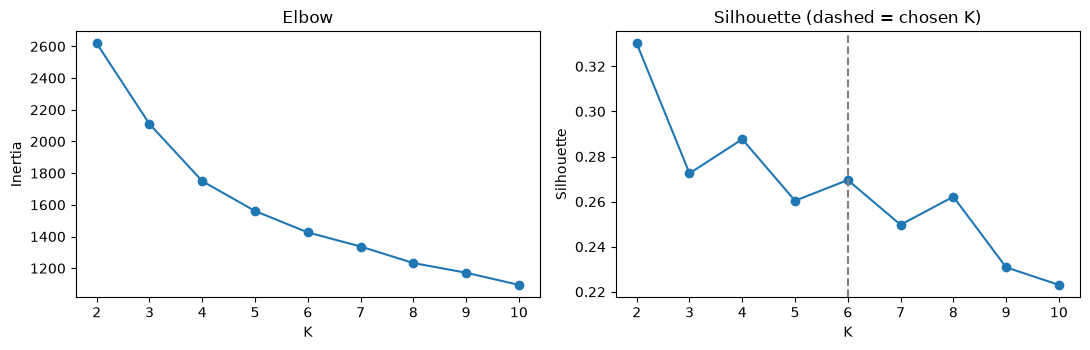

In [37]:
k_rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    k_rows.append(dict(K=k, Inertia=km.inertia_, Silhouette=silhouette_score(X, km.labels_),
                       Davies_Bouldin=davies_bouldin_score(X, km.labels_)))
k_sweep = pd.DataFrame(k_rows)
display(k_sweep.round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(k_sweep.K, k_sweep.Inertia, marker="o"); axes[0].set(xlabel="K", ylabel="Inertia", title="Elbow")
axes[1].plot(k_sweep.K, k_sweep.Silhouette, marker="o"); axes[1].axvline(K, ls="--", c="gray")
axes[1].set(xlabel="K", ylabel="Silhouette", title="Silhouette (dashed = chosen K)")
plt.tight_layout(); plt.show()

## 10. Cluster interpretation and visualizations

Profiles show each cluster's mean standardized features. Representative station-windows are the observations closest to their cluster mean. The PCA projection is shared across panels; DBSCAN noise is gray.

BPGC profiles and representative station-windows


,check_in_share_00_07,check_in_share_07_10,check_in_share_10_16,check_in_share_16_20,check_in_share_20_24,check_out_share_00_07,check_out_share_07_10,check_out_share_10_16,check_out_share_16_20,check_out_share_20_24,net_flow_00_07,net_flow_07_10,net_flow_10_16,net_flow_16_20,net_flow_20_24,weekend_share,volume_share
cluster,,,,,,,,,,,,,,,,,
0,0.265,0.075,0.982,-0.389,-0.192,0.849,-0.513,-0.325,-0.154,0.954,-0.324,0.393,0.870,-0.102,-0.713,0.513,-0.657
1,-1.088,-1.104,-0.763,1.635,-0.482,1.114,1.755,-0.240,-1.557,-1.320,-1.484,-1.374,0.041,1.638,0.984,-1.061,-0.895
2,1.121,1.216,0.018,-0.943,-0.414,-0.592,-0.766,-0.583,0.986,0.729,1.085,1.069,0.355,-1.008,-0.829,-0.029,0.561
3,-0.822,-1.563,-2.356,0.237,3.671,-0.850,-0.236,2.045,0.255,-1.022,0.052,-1.383,-3.196,0.030,2.041,0.995,1.424
4,-0.464,-0.376,0.191,-0.320,1.143,-0.721,-0.589,1.143,0.504,-0.149,0.332,0.120,-0.874,-0.425,0.630,1.064,0.148
5,-0.472,-0.420,-0.077,0.560,-0.196,-0.068,0.578,0.146,-0.448,-0.508,-0.353,-0.651,-0.174,0.525,0.235,-0.460,0.153


,cluster,station,window,prototype_distance_sq
0,0,Al Qiyadah,W21/22,2.240
1,0,Etisalat,W21/22,2.334
2,0,centrepoint,W21/22,2.822
3,1,Al Khail,W24/25,1.210
4,1,Equiti,W18/19,1.440
5,1,Emirates,W21/22,1.473
6,2,Salah Al Din,W18/19,1.158
7,2,Abu Baker Al Siddique,W19/20,1.304
8,2,Abu Baker Al Siddique,W24/25,1.451
9,3,Burj Khalifa/ Dubai Mall,W19/20,0.908


DBSCAN profiles and representative station-windows


,check_in_share_00_07,check_in_share_07_10,check_in_share_10_16,check_in_share_16_20,check_in_share_20_24,check_out_share_00_07,check_out_share_07_10,check_out_share_10_16,check_out_share_16_20,check_out_share_20_24,net_flow_00_07,net_flow_07_10,net_flow_10_16,net_flow_16_20,net_flow_20_24,weekend_share,volume_share
cluster,,,,,,,,,,,,,,,,,
0,-0.009,0.056,-0.010,-0.012,-0.044,-0.182,0.005,-0.006,0.029,0.028,0.080,0.026,-0.065,-0.044,-0.076,-0.039,0.088
1,1.567,-0.114,0.750,-0.920,0.658,2.789,-0.519,0.121,-0.823,0.737,-0.240,0.412,0.959,0.203,0.119,0.116,-0.794
2,-1.201,-1.041,1.307,0.402,0.261,0.177,0.389,0.219,0.386,-1.330,-1.256,-0.960,0.938,0.201,1.464,0.688,0.086
3,-1.389,-1.474,-2.259,2.281,0.020,1.945,0.990,-0.788,-0.570,-1.143,-1.910,-1.469,-0.076,1.456,1.356,0.054,-1.242


,cluster,station,window,center_distance_sq
0,0,Financial Centre,W19/20,1.361
1,0,Financial Centre,W24/25,1.554
2,0,ONPASSIVE,W19/20,1.568
3,1,Airport Terminal 1,W18/19,1.034
4,1,Airport Terminal 3,W21/22,1.561
5,1,Airport Terminal 3,W19/20,2.634
6,2,Oud Metha,W18/19,0.358
7,2,Oud Metha,W19/20,0.772
8,2,Oud Metha,W21/22,0.988
9,3,Creek,W19/20,0.300


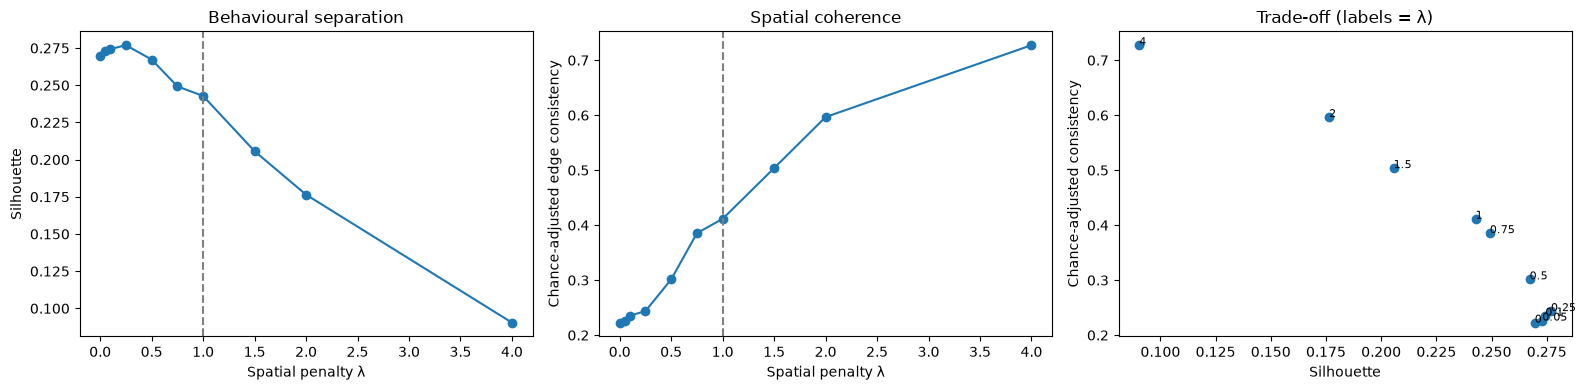

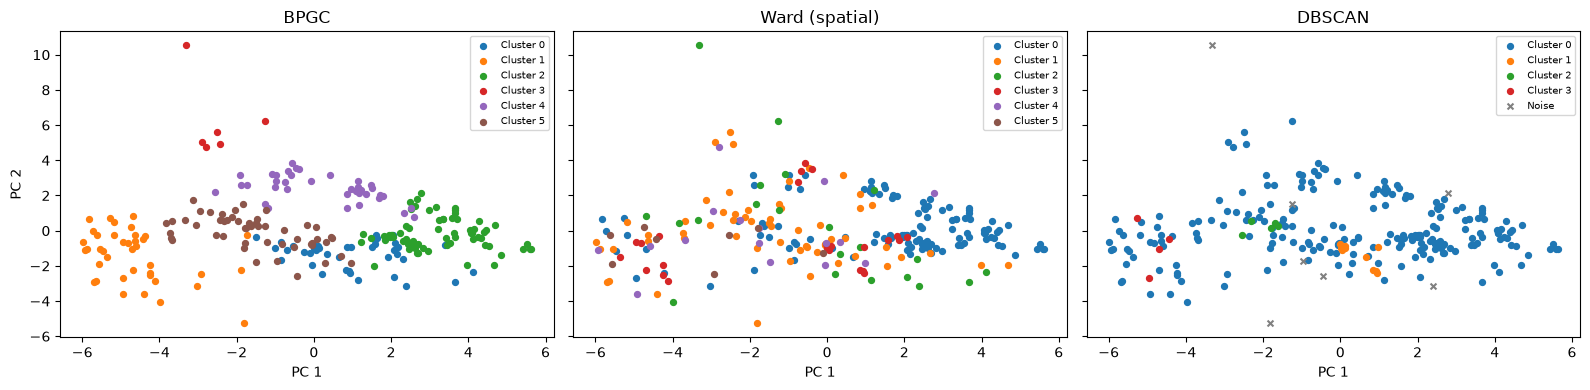

In [38]:
assignments = df[KEY_COLUMNS].copy()
assignments["cluster"] = bpgc_labels
assignments["ward_spatial_cluster"] = ward_sp_labels
assignments["dbscan_cluster"] = dbscan_labels

def cluster_tables(labels, distance_column):
    assigned = labels != -1
    profiles = df.loc[assigned, feature_cols].groupby(labels[assigned]).mean()
    profiles.index.name = "cluster"
    representatives = []
    for cluster, center in profiles.iterrows():
        indices = np.flatnonzero(labels == cluster)
        distances = sqdist(X[indices], center.to_numpy()[None, :]).ravel()
        for nearest in np.argsort(distances)[:3]:
            i = indices[nearest]
            representatives.append({"cluster": cluster, "station": df.loc[i, "station"],
                                    "window": df.loc[i, "win"], distance_column: distances[nearest]})
    columns = ["cluster", "station", "window", distance_column]
    return profiles, pd.DataFrame(representatives, columns=columns)

profiles, representatives = cluster_tables(bpgc_labels, "prototype_distance_sq")
dbscan_profiles, dbscan_representatives = cluster_tables(dbscan_labels, "center_distance_sq")
print("BPGC profiles and representative station-windows")
display(profiles.round(3)); display(representatives.round(3))
print("DBSCAN profiles and representative station-windows")
display(dbscan_profiles.round(3)); display(dbscan_representatives.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(sweep["Lambda"], sweep["Silhouette"], marker="o")
axes[0].axvline(best_lambda, ls="--", c="gray")
axes[0].set(xlabel="Spatial penalty λ", ylabel="Silhouette", title="Behavioural separation")
axes[1].plot(sweep["Lambda"], sweep["Spatial_Consistency_Adj"], marker="o")
axes[1].axvline(best_lambda, ls="--", c="gray")
axes[1].set(xlabel="Spatial penalty λ", ylabel="Chance-adjusted edge consistency", title="Spatial coherence")
axes[2].scatter(sweep["Silhouette"], sweep["Spatial_Consistency_Adj"])
for _, r in sweep.iterrows():
    axes[2].annotate(f"{r.Lambda:g}", (r.Silhouette, r.Spatial_Consistency_Adj), fontsize=8)
axes[2].set(xlabel="Silhouette", ylabel="Chance-adjusted consistency", title="Trade-off (labels = λ)")
plt.tight_layout(); plt.show()

projection = PCA(n_components=2).fit_transform(X)
panels = [("BPGC", bpgc_labels), ("Ward (spatial)", ward_sp_labels), ("DBSCAN", dbscan_labels)]
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)
for ax, (method, labels) in zip(axes, panels):
    for cluster in np.unique(labels[labels != -1]):
        pts = projection[labels == cluster]
        ax.scatter(pts[:, 0], pts[:, 1], s=18, label=f"Cluster {cluster}")
    noise = projection[labels == -1]
    if len(noise):
        ax.scatter(noise[:, 0], noise[:, 1], s=18, color="gray", marker="x", label="Noise")
    ax.set(xlabel="PC 1", title=method); ax.legend(fontsize=7)
axes[0].set_ylabel("PC 2")
fig.tight_layout(); plt.show()

## 11. Save outputs and print final results

In [39]:
comparison.to_csv(OUTPUT_DIR/"bpgc_model_comparison.csv", index=False)
sweep.to_csv(OUTPUT_DIR/"bpgc_lambda_sweep.csv", index=False)
ncut.to_csv(OUTPUT_DIR/"bpgc_normalized_cut.csv", index=False)
stability.to_csv(OUTPUT_DIR/"bpgc_stability_summary.csv", index=False)
stability_repeats.to_csv(OUTPUT_DIR/"bpgc_stability_repeats.csv", index=False)
paired.to_csv(OUTPUT_DIR/"bpgc_stability_paired.csv", index=False)
k_sweep.to_csv(OUTPUT_DIR/"bpgc_k_sweep.csv", index=False)
assignments.to_csv(OUTPUT_DIR/"bpgc_labels.csv", index=False)
profiles.to_csv(OUTPUT_DIR/"bpgc_cluster_profiles.csv")
representatives.to_csv(OUTPUT_DIR/"bpgc_representative_stations.csv", index=False)
dbscan_profiles.to_csv(OUTPUT_DIR/"dbscan_cluster_profiles.csv")
dbscan_representatives.to_csv(OUTPUT_DIR/"dbscan_representative_stations.csv", index=False)
print("FINAL RESULTS — BPGC vs baselines"); display(comparison.round(4))
print("NORMALIZED CUT"); display(ncut.round(4))
print("STABILITY"); display(stability.round(4))
print("PAIRED STABILITY vs K-Means"); display(paired.round(4))
print("Selected λ:", best_lambda, "| max-silhouette λ:", max_sil_lambda)
print("Files saved to:", OUTPUT_DIR)
print("Interpretation: weigh separation, chance-adjusted spatial consistency and paired stability together; "
      "DBSCAN figures are not meaningful if its largest-cluster share is near 1.")

FINAL RESULTS — BPGC vs baselines


,Method,N,Clusters,Noise_Points,Coverage,Silhouette,Davies_Bouldin,Calinski_Harabasz,SSE,Spatial_Consistency,Spatial_Consistency_Adj,Spatial_Edge_Coverage,Smallest_Cluster,Largest_Cluster,Largest_Cluster_Share,Eps,Min_Samples
0,K-Means,244,6,0,1.0000,0.2696,1.3129,90.8593,1426.0136,0.3893,0.2227,1.0000,6,72,0.2951,NaN,NaN
1,Ward,244,6,0,1.0000,0.2785,1.3151,81.7876,1525.9942,0.4795,0.3179,1.0000,6,83,0.3402,NaN,NaN
2,Ward (spatial),244,6,0,1.0000,0.0314,4.9856,10.5276,3396.7504,0.9549,0.9334,1.0000,8,116,0.4754,NaN,NaN
3,BPGC (λ=1),244,6,0,1.0000,0.2428,1.3388,81.4387,1530.1204,0.5369,0.4115,1.0000,6,70,0.2869,NaN,NaN
4,DBSCAN,244,4,7,0.9713,-0.0124,1.2063,8.1086,3477.5383,0.8957,0.2543,0.9426,4,218,0.9198,2.6423,5.0


NORMALIZED CUT


,Method,Partitions,Noise_Points,Ncut (same graph),Ncut_ratio
0,K-Means,6,0,4.6204,0.9241
1,Ward,6,0,4.6315,0.9263
2,Ward (spatial),6,0,4.8347,0.9669
3,BPGC (λ=1),6,0,4.6252,0.9250
4,DBSCAN,5,7,3.9515,0.9879


STABILITY


,Method,mean,std,min,max
0,BPGC,0.8408,0.0857,0.6714,0.9871
1,DBSCAN,0.9352,0.0838,0.6881,1.0000
2,K-Means,0.8803,0.0988,0.6523,0.9851
3,Ward,0.7522,0.1259,0.5108,0.9749
4,Ward (spatial),0.2001,0.0995,0.0751,0.3846


PAIRED STABILITY vs K-Means


,Method,Mean_diff_vs_KMeans,SE,Diff_over_SE
0,BPGC,-0.0395,0.0251,-1.5734
1,DBSCAN,0.0549,0.0294,1.8663
2,Ward,-0.1281,0.0390,-3.2820
3,Ward (spatial),-0.6802,0.0319,-21.3031


Selected λ: 1.0 | max-silhouette λ: 0.25
Files saved to: /Users/aryanchandra/Downloads/Metro-Spectral-STGRSC/results/bpgc
Interpretation: weigh separation, chance-adjusted spatial consistency and paired stability together; DBSCAN figures are not meaningful if its largest-cluster share is near 1.
